# E-Commerce Sales Data Visualization Project


### 1. Load Sales Dataset


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")

csv_path = "../csv/sales_data.csv" if os.path.exists("../csv/sales_data.csv") else "csv/sales_data.csv"
df = pd.read_csv(csv_path)

print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:\n", df.head())


Dataset Shape: (150, 9)

First 5 rows:
   order_id month     category region  units_sold  unit_price  revenue  profit  customer_rating
0      5001   Mar       Sports  North           8       59.48   475.84  140.53              3.5
1      5002   Jun  Electronics   West           2      373.29   746.58  205.70              4.2
2      5003   May  Electronics   West           3      405.77  1217.31  385.96              4.8
3      5004   Apr     Clothing  South           9       76.26   686.34  196.18              3.8
4      5005   Feb       Sports   East           7      144.59  1012.13  134.31              4.3


### 2. Summary Statistics & Category Breakdown


In [2]:
print(f"Total Revenue: ${df['revenue'].sum():,.2f}")
print(f"Total Profit:  ${df['profit'].sum():,.2f}\n")

cat_summary = df.groupby("category").agg(
    total_orders=("order_id", "count"),
    total_units=("units_sold", "sum"),
    total_revenue=("revenue", "sum"),
    total_profit=("profit", "sum"),
    avg_rating=("customer_rating", "mean")
).round(2).reset_index()

print("Category Summary:")
print(cat_summary.to_string(index=False))


Total Revenue: $147,080.36
Total Profit:  $32,354.51

Category Summary:
      category  total_orders  total_units  total_revenue  total_profit  avg_rating
         Books            23          129        5005.86       1217.63        4.22
      Clothing            30          151       13110.02       2819.68        4.17
   Electronics            44          183       77130.04      16977.53        4.24
Home & Kitchen            38          228       41707.11       9380.71        4.06
        Sports            15           80       10127.33       1958.96        4.00


### 3. Monthly Revenue & Profit Trend (Line Plot)


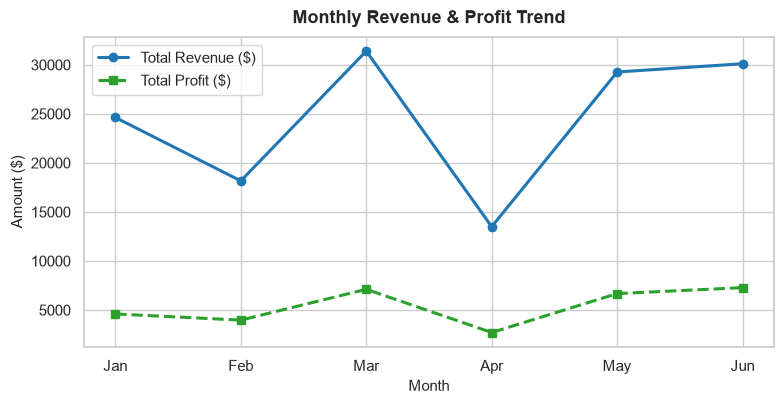

In [3]:
month_order = ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]
monthly_stats = df.groupby("month")[["revenue", "profit"]].sum().reindex(month_order)

plt.figure(figsize=(8, 4.2))
plt.plot(monthly_stats.index, monthly_stats["revenue"], marker='o', linewidth=2.2, color='#1f77b4', label='Total Revenue ($)')
plt.plot(monthly_stats.index, monthly_stats["profit"], marker='s', linewidth=2.2, linestyle='--', color='#2ca02c', label='Total Profit ($)')

plt.title("Monthly Revenue & Profit Trend", fontsize=13, fontweight='bold', pad=10)
plt.xlabel("Month", fontsize=11)
plt.ylabel("Amount ($)", fontsize=11)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


### 4. Category & Regional Sales Comparison (Bar Charts)


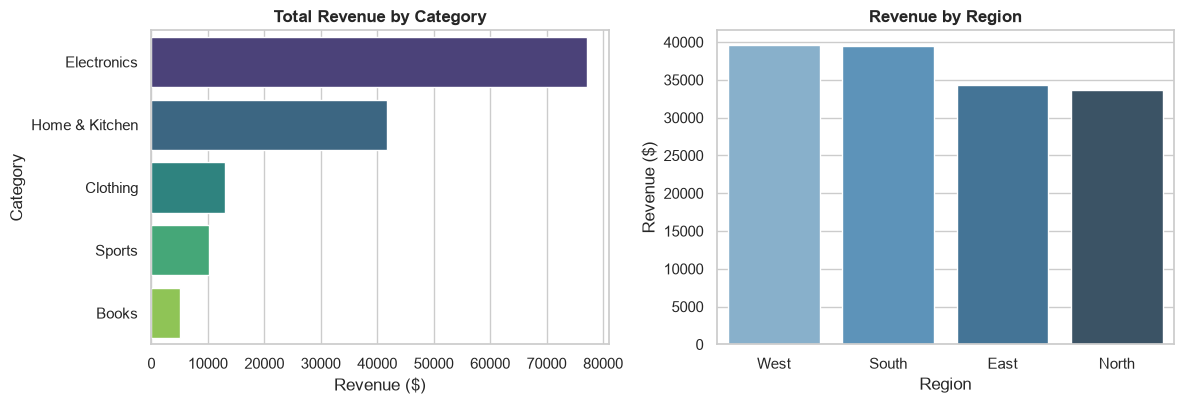

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

cat_rev = df.groupby("category")["revenue"].sum().sort_values(ascending=False)
sns.barplot(x=cat_rev.values, y=cat_rev.index, hue=cat_rev.index, palette="viridis", legend=False, ax=axes[0])
axes[0].set_title("Total Revenue by Category", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Revenue ($)")
axes[0].set_ylabel("Category")

reg_rev = df.groupby("region")["revenue"].sum().sort_values(ascending=False)
sns.barplot(x=reg_rev.index, y=reg_rev.values, hue=reg_rev.index, palette="Blues_d", legend=False, ax=axes[1])
axes[1].set_title("Revenue by Region", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Region")
axes[1].set_ylabel("Revenue ($)")

plt.tight_layout()
plt.show()


### 5. Revenue Distribution & Profit Outliers (Histogram & Boxplot)


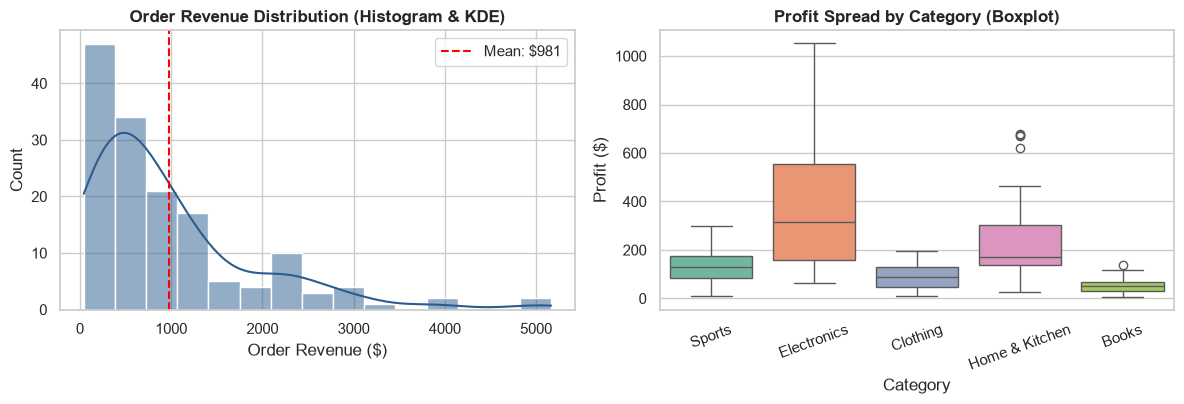

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

sns.histplot(df["revenue"], kde=True, color="#2b5c8f", bins=15, ax=axes[0])
axes[0].axvline(df["revenue"].mean(), color='red', linestyle='--', label=f"Mean: ${df['revenue'].mean():.0f}")
axes[0].set_title("Order Revenue Distribution (Histogram & KDE)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Order Revenue ($)")
axes[0].set_ylabel("Count")
axes[0].legend()

sns.boxplot(data=df, x="category", y="profit", hue="category", palette="Set2", legend=False, ax=axes[1])
axes[1].set_title("Profit Spread by Category (Boxplot)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Category")
axes[1].set_ylabel("Profit ($)")
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()


### 6. Revenue vs Profit Relationship & Correlation Heatmap


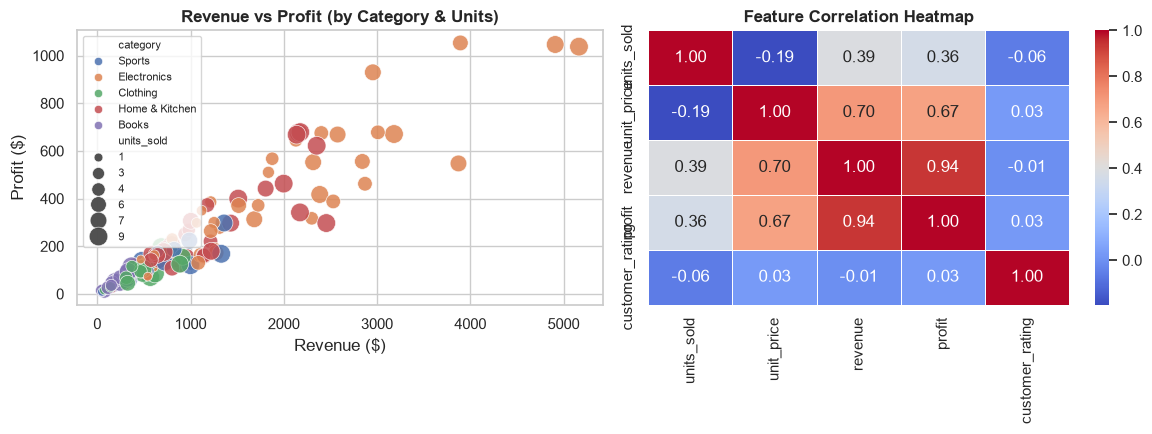

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.scatterplot(
    data=df, x="revenue", y="profit", hue="category", size="units_sold",
    sizes=(40, 180), alpha=0.85, palette="deep", ax=axes[0]
)
axes[0].set_title("Revenue vs Profit (by Category & Units)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Revenue ($)")
axes[0].set_ylabel("Profit ($)")
axes[0].legend(fontsize=8, loc='upper left')

corr = df[["units_sold", "unit_price", "revenue", "profit", "customer_rating"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5, ax=axes[1])
axes[1].set_title("Feature Correlation Heatmap", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


### 7. Save Category Summary to CSV


In [7]:
out_dir = "../csv" if os.path.exists("../csv") else "csv"
os.makedirs(out_dir, exist_ok=True)
out_file = os.path.join(out_dir, "sales_category_summary.csv")

cat_summary.to_csv(out_file, index=False)
print(f"Saved summary to: {out_file}")


Saved summary to: csv\sales_category_summary.csv
